### Neural Network Basic
A Neural Network is basically a function that is capable of capture highly nonlinearity given the network is deep enough and massive training data. In RL, Neural Networks play a center role which usually used to model:

-> A policy:
$$
\pi_{\theta}(a|s) = f_{\theta}(s)
$$
where $f_{\theta}(s)$ represents a Neural Network with parameter vector $\theta$.

If the policy is stochastic, the output of the NN is a probablity distribution over the Action Space. An action then can be sampled from this ditribution to interact with the environment

We first getting started with building and training a Neural Network

In [2]:
import torch
from torch.nn import Module # Neural Network Module
from torch import nn
import numpy as np

from typing import Union

print (torch.__version__)


2.9.1+cu126


In [3]:
device = None
use_gpu = False
gpu_id=0
if torch.cuda.is_available() and use_gpu:
    device = torch.device("cuda:" + str(gpu_id))
    print("Using GPU id {}".format(gpu_id))
else:
    device = torch.device("cpu")
    print("Using CPU.")

Using CPU.


/home/vanthanhnguyen/miniconda3/envs/torch_and_RL/lib/python3.10/site-packages/torch/cuda/__init__.py:182: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0


We write a supporting function that build a Neural Network

In [4]:
Activation = Union[str, nn.Module] # Union type, an activation can be a string or a nn.module

# Dictionary of activation function type
_str_to_activation = {
    'relu': nn.ReLU(),
    'tanh': nn.Tanh(),
    'leaky_relu': nn.LeakyReLU(),
    'sigmoid': nn.Sigmoid(),
    'selu': nn.SELU(),
    'softplus': nn.Softplus(),
    'identity': nn.Identity(),
}

def build_mlp(
        input_size: int,
        output_size: int,
        n_layers: int,
        size: int,
        activation: Activation = 'tanh',
        output_activation: Activation = 'identity',
):
    """
        Builds a feedforward neural network

        arguments:
            input_placeholder: placeholder variable for the state (batch_size, input_size)
            scope: variable scope of the network

            n_layers: number of hidden layers
            size: dimension of each hidden layer
            activation: activation of each hidden layer

            input_size: size of the input layer
            output_size: size of the output layer
            output_activation: activation of the output layer

        returns:
            output_placeholder: the result of a forward pass through the hidden layers + the output layer
    """
    if isinstance(activation, str):
        activation = _str_to_activation[activation]
    if isinstance(output_activation, str):
        output_activation = _str_to_activation[output_activation]
    layers = []
    in_size = input_size
    for _ in range(n_layers):
        layers.append(nn.Linear(in_size, size))
        layers.append(activation)
        in_size = size
    layers.append(nn.Linear(in_size, output_size))
    layers.append(output_activation)

    mlp = nn.Sequential(*layers)
    mlp.to(device)
    return mlp

### Neural Network as a function approximation
A neural network is basically a function. In the example below, we will build and train a Neural Network to approximate a nonlinear function:
$$
f_{\theta}(x,y) \approx z(x,y)
$$

In [5]:
# Neural network parameter
input_size = 2
output_size = 1 
n_layers = 3 # number of hidden layer
size = 64

nn_f = build_mlp(input_size = input_size, output_size = output_size, n_layers = n_layers, size=size)
nn_f

Sequential(
  (0): Linear(in_features=2, out_features=64, bias=True)
  (1): Tanh()
  (2): Linear(in_features=64, out_features=64, bias=True)
  (3): Tanh()
  (4): Linear(in_features=64, out_features=64, bias=True)
  (5): Tanh()
  (6): Linear(in_features=64, out_features=1, bias=True)
  (7): Identity()
)

We approximate the following function:
$$
z(x,y) = \sin(x)  \cos(y)
$$

First we generate some training data

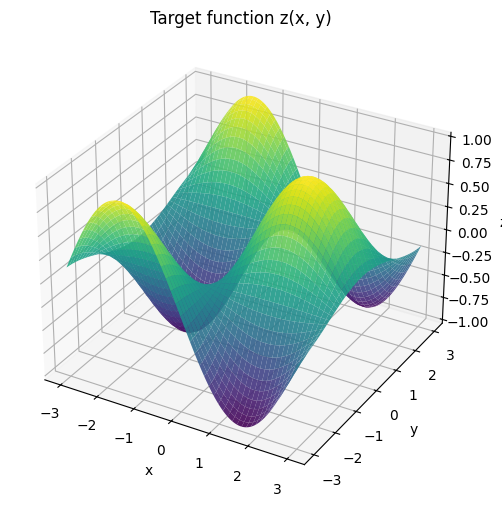

In [6]:
x = np.linspace(-3,3,200)
y = np.linspace(-3,3,200)

X,Y = np.meshgrid(x,y)

def z_xy (x: np.float32, y:np.float32) -> np.float32:
    return np.sin(x)*np.cos(y)
    #return np.sin(x**2 + y**2)/(x**2 + y**2) # too complicated
Z = z_xy(X,Y)

# Ploting the function
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # optional, for 3D plotting
fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.9)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title('Target function z(x, y)')
plt.show()

Now we process the data for the training

In [7]:
# Flatten X and Y
X_flat = X.ravel()
Y_flat = Y.ravel()

print(X_flat.shape) # (40000,)
print(Y_flat.shape) # (40000,)

# stack to input
XY_stack = np.column_stack((X_flat, Y_flat))
print(XY_stack.shape) # (40000,2) (number_of_samples, input_dim)

# Convert to torch tensor
XY_train = torch.tensor(XY_stack, dtype=torch.float32)
Z_train = torch.tensor(Z.reshape(-1,1), dtype=torch.float32)

print(XY_train.shape)
print(Z_train.shape)

(40000,)
(40000,)
(40000, 2)
torch.Size([40000, 2])
torch.Size([40000, 1])


Now we setup some training components

The loss function is defined as the Mean Square Error function:

$$
L(\theta)=\frac{1}{N}\sum_{i=1}^{N}
\left(f_\theta(x_i,y_i)-z_i\right)^2.
$$

In [8]:
criterion = nn.MSELoss() # Loss function

optimizer = torch.optim.Adam(
    nn_f.parameters(),
    lr=1e-3
)

A training epoch perform the following steps:
1. Forward propagation: calculate predictions.
2. Calculate the loss.
3. Backpropagation: compute gradients.
4. Optimizer step: update the parameters.

#### Full-batch Training
The training process keep iterating on the whole training data set above

In [9]:
num_epochs = 400 # Number of training epoches/iteration
loss_log = []

for epoch in range(num_epochs):    
    # 1: forward pass
    predictions = nn_f (XY_train)

    # 2: calculate Loss
    loss = criterion(predictions, Z_train)

    # 3: Backpropagation: compute gradients
    optimizer.zero_grad()
    loss.backward()

    # 4. Update parameters
    optimizer.step()

    # log the loss
    loss_log.append(loss)

    # print the training process
    if (epoch + 1) % 10 == 0:
            print(
                f"Epoch [{epoch+1}/{num_epochs}], "
                f"Loss: {loss.item():.8f}"
            )

Epoch [10/400], Loss: 0.18880437
Epoch [20/400], Loss: 0.10296467
Epoch [30/400], Loss: 0.04538926
Epoch [40/400], Loss: 0.03285936
Epoch [50/400], Loss: 0.01970444
Epoch [60/400], Loss: 0.01367925
Epoch [70/400], Loss: 0.01194397
Epoch [80/400], Loss: 0.01065718
Epoch [90/400], Loss: 0.00966982
Epoch [100/400], Loss: 0.00897702
Epoch [110/400], Loss: 0.00835601
Epoch [120/400], Loss: 0.00781434
Epoch [130/400], Loss: 0.00733550
Epoch [140/400], Loss: 0.00691022
Epoch [150/400], Loss: 0.00652991
Epoch [160/400], Loss: 0.00618438
Epoch [170/400], Loss: 0.00586661
Epoch [180/400], Loss: 0.00556985
Epoch [190/400], Loss: 0.00597095
Epoch [200/400], Loss: 0.00506934
Epoch [210/400], Loss: 0.00486338
Epoch [220/400], Loss: 0.00464921
Epoch [230/400], Loss: 0.00445745
Epoch [240/400], Loss: 0.00425091
Epoch [250/400], Loss: 0.00405766
Epoch [260/400], Loss: 0.00386921
Epoch [270/400], Loss: 0.00371561
Epoch [280/400], Loss: 0.00364131
Epoch [290/400], Loss: 0.00357996
Epoch [300/400], Loss: 

#### Model Evaluation
We now plot the figure to visualize the model performance

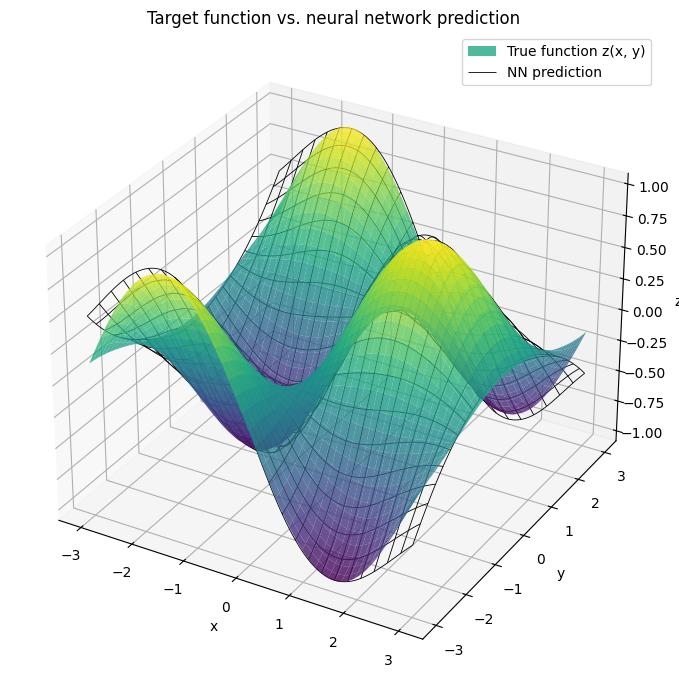

In [10]:
# Plot the comparison figure
with torch.no_grad():
    XY_eval = torch.tensor(np.column_stack((X.ravel(), Y.ravel())), dtype=torch.float32)
    pred_flat = nn_f(XY_eval).cpu().numpy().reshape(X.shape)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.8)
wire = ax.plot_wireframe(X, Y, pred_flat, rstride=8, cstride=8, color='black', linewidth=0.6)

ax.set_title('Target function vs. neural network prediction')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

ax.legend([surf, wire], ['True function z(x, y)', 'NN prediction'], loc='upper right')

plt.tight_layout()
plt.show()

#### Mini-batch training
Instead of passing the whole training data in each epoch (full-batch training), in mini-batch training, we randomly sample a batch (subset) of the training data set to use for each epoch 

In [57]:
# make a new network
# Neural network parameter

input_size = 2
output_size = 1 
n_layers = 4 # number of hidden layer
size = 64

nn_f_2 = build_mlp(input_size = input_size, output_size = output_size, n_layers = n_layers, size=size)

criterion = nn.MSELoss() # Loss function

optimizer = torch.optim.Adam(
    nn_f_2.parameters(),
    lr=1e-3
)

num_samples = len(Z_train)
print(num_samples)

batch_size = 1000 # number of training data point in each epoch
idx_list = np.arange(num_samples)

print(idx_list.shape)

num_epoches = 1000

rng = np.random.default_rng()

# batch_idx = rng.choice(idx_list, batch_size, replace= True)
# XY_batch = XY_train[batch_idx]
# XY_batch

for epoch in range(num_epoches):

    # randomly sample a batch from training data set
    batch_idx = rng.choice(idx_list, batch_size, replace= True)
    XY_batch = XY_train[batch_idx]
    Z_batch = Z_train[batch_idx]

    # Prediction
    predictions = nn_f_2(XY_batch)

    # 2: calculate Loss
    loss = criterion(predictions, Z_batch)

    # 3: Backpropagation: compute gradients
    optimizer.zero_grad()
    loss.backward()

    # 4. Update parameters
    optimizer.step()

    # print the training process
    if (epoch + 1) % 50 == 0:
            print(
                f"Epoch [{epoch+1}/{num_epoches}], "
                f"Loss: {loss.item():.8f}"
            )

# Evaluate on the whole data set
predictions = nn_f_2(XY_train)
loss = criterion(predictions, Z_train)

print("Total Loss on training data: ", loss)

40000
(40000,)
Epoch [50/1000], Loss: 0.02591241
Epoch [100/1000], Loss: 0.00995514
Epoch [150/1000], Loss: 0.00894925
Epoch [200/1000], Loss: 0.00752152
Epoch [250/1000], Loss: 0.00610970
Epoch [300/1000], Loss: 0.00566194
Epoch [350/1000], Loss: 0.00476617
Epoch [400/1000], Loss: 0.00505604
Epoch [450/1000], Loss: 0.00441145
Epoch [500/1000], Loss: 0.00466276
Epoch [550/1000], Loss: 0.00366732
Epoch [600/1000], Loss: 0.00363761
Epoch [650/1000], Loss: 0.00350762
Epoch [700/1000], Loss: 0.00339059
Epoch [750/1000], Loss: 0.00271598
Epoch [800/1000], Loss: 0.00267311
Epoch [850/1000], Loss: 0.00322557
Epoch [900/1000], Loss: 0.00204988
Epoch [950/1000], Loss: 0.00226236
Epoch [1000/1000], Loss: 0.00166259
Total Loss on training data:  tensor(0.0020, grad_fn=<MseLossBackward0>)


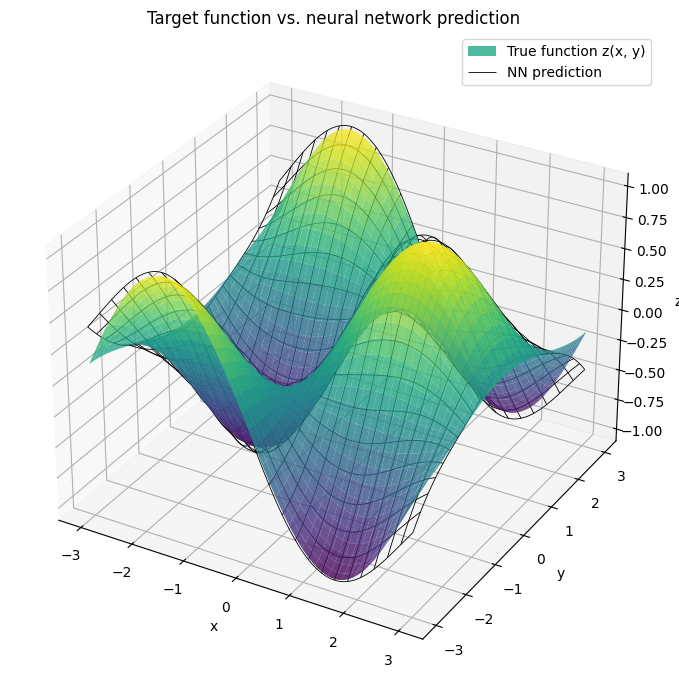

In [58]:
# Plot the comparison figure
with torch.no_grad():
    XY_eval = torch.tensor(np.column_stack((X.ravel(), Y.ravel())), dtype=torch.float32)
    pred_flat = nn_f_2(XY_eval).cpu().numpy().reshape(X.shape)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none', alpha=0.8)
wire = ax.plot_wireframe(X, Y, pred_flat, rstride=8, cstride=8, color='black', linewidth=0.6)

ax.set_title('Target function vs. neural network prediction')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

ax.legend([surf, wire], ['True function z(x, y)', 'NN prediction'], loc='upper right')

plt.tight_layout()
plt.show()